# EMQA_L6_rogb_summer

**Summer 2026: Romania exports at midday and buys from Bulgaria in the evening**

Energy Markets Quantitative Analysis (EMQA), Lecture 6 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L6/EMQA_L6_rogb_summer/EMQA_L6_rogb_summer.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

## Setup: chart style and data period

In [2]:
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

# course chart style: transparent background, no grid, legend at the bottom outside the axes, fixed colour per zone
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}
ZONE_LS = {'RO': '-', 'BG': '--', 'HU': '-.', 'DE_LU': ':'}
ZN = {'RO': 'Romania', 'BG': 'Bulgaria', 'HU': 'Hungary', 'DE_LU': 'Germany-Lux.'}
INK = '#222222'
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': INK, 'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK,
    'text.color': INK, 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})


def legend_bottom(fig, ncol=4):
    """One legend for the whole figure, centred under the axes, outside the plotting area."""
    handles, labels = [], []
    for ax in fig.axes:
        for h, l in zip(*ax.get_legend_handles_labels()):
            if l not in labels:
                handles.append(h)
                labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, 0.0), frameon=False,
               handlelength=2.0, columnspacing=1.2)


def fl(x, k=4):
    """Rounding used for the numbers of the slides."""
    return None if x is None or np.isnan(float(x)) else round(float(x), k)


def show_numbers(d):
    for k, v in d.items():
        print(f'{k:<34} {v}')

Hours are Romanian local time. Midday window: 12:00-15:00; evening window: 19:00-23:00. Moldova and Ukraine borders are only partly reported, so 'all borders' is mostly Bulgaria, Hungary and Serbia.

In [3]:
Y = 2026
TZL = 'Europe/Bucharest'
CB = pd.read_csv(DATA + 'crossborder_ro_mw_hourly_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
CB.index = pd.to_datetime(CB.index, utc=True).tz_convert(TZL)
PH = pd.read_csv(DATA + 'power_da_prices_hourly_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
PH.index = pd.to_datetime(PH.index, utc=True).tz_convert(TZL)
summer = (CB.index.year == Y) & CB.index.month.isin([6, 7, 8])
RG = CB.loc[summer, ['bulgaria', 'hungary', 'serbia', 'sum']].join(PH[['RO', 'BG']], how='left')
H = RG.groupby(RG.index.hour).mean()
mid_h = RG[RG.index.hour.isin([12, 13, 14])]
eve_h = RG[RG.index.hour.isin([19, 20, 21, 22])]
mid = mid_h.groupby(mid_h.index.normalize())['bulgaria'].mean()
eve = eve_h.groupby(eve_h.index.normalize())['bulgaria'].mean()
hb = int(H['bulgaria'].idxmax())
show_numbers({'rogb.n_days': int(len(RG.index.normalize().unique())),
              'rogb.exp_mw': fl(-H['sum'].min(), 0), 'rogb.imp_mw': fl(H['sum'].max(), 0),
              'rogb.hu_mid_mw': fl(-H.loc[12, 'hungary'], 0), 'rogb.rs_mid_mw': fl(-H.loc[12, 'serbia'], 0),
              'rogb.bg_eve_h': hb, 'rogb.bg_eve_mw': fl(H['bulgaria'].max(), 0),
              'rogb.days_bg_eve_imp': int((eve > 0).sum()), 'rogb.n_days_mid': int((mid < 0).sum()),
              'rogb.p_ro_eve': fl(H.loc[hb, 'RO'], 1), 'rogb.p_bg_eve': fl(H.loc[hb, 'BG'], 1),
              'rogb.p_gap_eve': fl(H.loc[hb, 'RO'] - H.loc[hb, 'BG'], 1)})

rogb.n_days                        92
rogb.exp_mw                        960.0
rogb.imp_mw                        1582.0
rogb.hu_mid_mw                     857.0
rogb.rs_mid_mw                     367.0
rogb.bg_eve_h                      21
rogb.bg_eve_mw                     2064.0
rogb.days_bg_eve_imp               92
rogb.n_days_mid                    43
rogb.p_ro_eve                      243.9
rogb.p_bg_eve                      178.3
rogb.p_gap_eve                     65.6


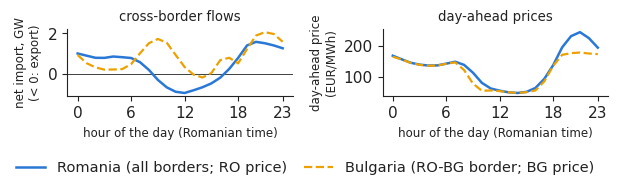

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(6.4, 1.95))
hh = H.index.values
axs[0].axhline(0, color=INK, lw=0.6)
axs[0].plot(hh, H['sum'] / 1000, color=PAL['RO'], lw=1.8, label='Romania (all borders; RO price)')
axs[0].plot(hh, H['bulgaria'] / 1000, color=PAL['BG'], lw=1.6, ls='--', label='Bulgaria (RO-BG border; BG price)')
axs[0].set_ylabel('net import, GW\n(< 0: export)', fontsize=8.5)
axs[0].set_title('cross-border flows', fontsize=9.5)
axs[1].plot(hh, H['RO'], color=PAL['RO'], lw=1.8)
axs[1].plot(hh, H['BG'], color=PAL['BG'], lw=1.6, ls='--')
axs[1].set_title('day-ahead prices', fontsize=9.5)
axs[1].set_ylabel('day-ahead price\n(EUR/MWh)', fontsize=8.5)
for ax in axs:
    ax.set_xticks([0, 6, 12, 18, 23])
    ax.set_xlabel('hour of the day (Romanian time)', fontsize=8.5)
legend_bottom(fig, ncol=2)
fig.subplots_adjust(wspace=0.45)
fig.canvas.draw()
legend_h = max([lg.get_window_extent().height for lg in fig.legends] or [0.0]) / fig.bbox.height
fig.tight_layout(rect=(0, legend_h + 0.035, 1, 1))
plt.savefig('rogb_summer.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()